Importing Required Libraries

In [1]:
import tensorflow as tf
print(tf.__version__)

from tensorflow.keras import layers, models
print("Keras working ✅")

2.19.0
Keras working ✅


In [2]:
# Core
import os
import numpy as np
import pandas as pd
import random

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ML utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# Deep learning
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.efficientnet_v2 import EfficientNetV2B0, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Seeds
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

Mounting Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Defining Dataset Paths

In [4]:
IMAGE_ROOT = "/content/drive/MyDrive/Capstone/NEU-DET"

TRAIN_DIR = os.path.join(IMAGE_ROOT, "train/images")
VAL_DIR   = os.path.join(IMAGE_ROOT, "validation/images")

TABULAR_PATH = "/content/drive/MyDrive/Capstone/equipment_anomaly_data.csv"

IMG_SIZE = 224
BATCH_SIZE = 32

**IMAGE DATASET EDA**

In [5]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    shear_range=0.1,
    horizontal_flip=True
)

val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_images = train_gen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_images = val_gen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

Found 1441 images belonging to 6 classes.
Found 360 images belonging to 6 classes.


Class Distribution

In [6]:
class_weights_img = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_images.classes),
    y=train_images.classes
)
class_weights_img = dict(enumerate(class_weights_img))

Load Tabular Data

In [7]:
df = pd.read_csv(TABULAR_PATH)

if "timestamp" not in df.columns:
    df["timestamp"] = pd.date_range(start="2024-01-01", periods=len(df), freq="T")

df = df.sort_values("timestamp").reset_index(drop=True)

**TABULAR DATASET PREPROCESSING**

In [8]:
le_equipment = LabelEncoder()
le_location = LabelEncoder()

df["equipment"] = le_equipment.fit_transform(df["equipment"])
df["location"] = le_location.fit_transform(df["location"])

features = ["temperature", "pressure", "vibration", "humidity", "equipment", "location"]
target = "faulty"

scaler = StandardScaler()
df[features] = scaler.fit_transform(df[features])

Time-Series Creation

In [9]:
WINDOW_SIZE = 10

X_seq, y_seq = [], []

for i in range(len(df) - WINDOW_SIZE):
    X_seq.append(df[features].iloc[i:i+WINDOW_SIZE].values)
    y_seq.append(df[target].iloc[i+WINDOW_SIZE])

X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

Test - Train Split

In [10]:
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq, y_seq,
    test_size=0.2,
    random_state=42,
    stratify=y_seq
)

Class Weights LSTM

In [11]:
class_weights_ts = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_seq),
    y=y_train_seq
)
class_weights_ts = dict(enumerate(class_weights_ts))

**IMAGE MODEL**

In [44]:
base_model = EfficientNetV2B0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

for layer in base_model.layers[:-50]:
    layer.trainable = False
for layer in base_model.layers[-50:]:
    layer.trainable = True

image_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(6, activation="softmax")
])

image_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(patience=3)

image_model.fit(
    train_images,
    validation_data=val_images,
    epochs=25,
    class_weight=class_weights_img,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.5350 - loss: 1.3322 - val_accuracy: 0.8000 - val_loss: 1.2343 - learning_rate: 1.0000e-04
Epoch 2/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 25s 549ms/step - accuracy: 0.8931 - loss: 0.3339 - val_accuracy: 0.9361 - val_loss: 0.7619 - learning_rate: 1.0000e-04
Epoch 3/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 25s 529ms/step - accuracy: 0.9341 - loss: 0.2036 - val_accuracy: 0.9611 - val_loss: 0.4678 - learning_rate: 1.0000e-04
Epoch 4/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 26s 571ms/step - accuracy: 0.9598 - loss: 0.1264 - val_accuracy: 0.9694 - val_loss: 0.3039 - learning_rate: 1.0000e-04
Epoch 5/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 26s 565ms/step - accuracy: 0.9611 - loss: 0.1098 - val_accuracy: 0.9667 - val_loss: 0.1625 - learning_rate: 1.0000e-04
Epoch 6/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 25s 547ms/step - accuracy: 0.9792 - loss: 0.0663 - val_accuracy: 0.9667 - val_loss: 0.1294 - learning_rate: 1.0000e-04
Epoch 7/25
46/46 ━━━━━━━━━━━━━━━━━━━━ 24s 522ms/step - accura

**LSTM MODEL**

In [45]:
lstm_model = models.Sequential([
    layers.LSTM(64, return_sequences=True, input_shape=(WINDOW_SIZE, X_seq.shape[2])),
    layers.Dropout(0.3),

    layers.LSTM(32),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [46]:
from tensorflow.keras.optimizers import Adam

lstm_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [47]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_lstm = EarlyStopping(patience=30, restore_best_weights=True)

In [48]:
lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_ts,
    callbacks=[early_stop_lstm]
)

Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.5590 - loss: 0.6917 - val_accuracy: 0.2953 - val_loss: 0.7057
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5164 - loss: 0.6898 - val_accuracy: 0.3785 - val_loss: 0.7030
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5813 - loss: 0.6881 - val_accuracy: 0.4853 - val_loss: 0.6947
Epoch 4/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5717 - loss: 0.6873 - val_accuracy: 0.4405 - val_loss: 0.7014
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5619 - loss: 0.6876 - val_accuracy: 0.4527 - val_loss: 0.7078
Epoch 6/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5774 - loss: 0.6869 - val_accuracy: 0.5000 - val_loss: 0.7048
Epoch 7/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5858 - loss: 0.6858 - val_accuracy: 0.5392 - val_loss: 0.6959
Epoch 8/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5798 - loss: 0.6834 - val_accuracy:

FUSION

In [53]:
# Use LSTM predictions directly (aligned data)
ts_probs = lstm_model.predict(X_test_seq).flatten()

# Proper threshold
y_true = y_test_seq
fusion_pred = (ts_probs > 0.6).astype(int)

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


**EVALUATION**

Fusion Accuracy: 0.9001956947162426
Fusion Precision: 0.0
Fusion Recall: 0.0
Fusion F1 Score: 0.0


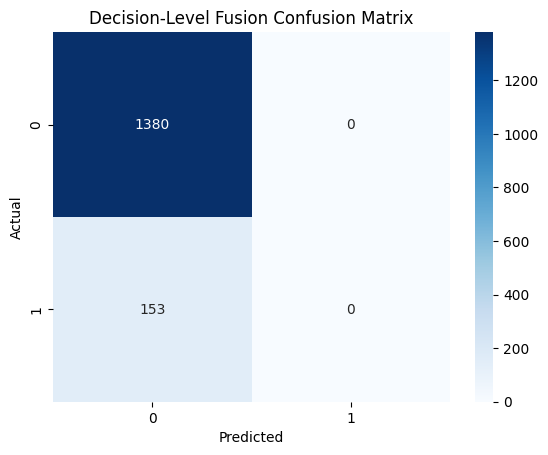

In [54]:
print("Fusion Accuracy:", accuracy_score(y_true, fusion_pred))
print("Fusion Precision:", precision_score(y_true, fusion_pred, zero_division=0))
print("Fusion Recall:", recall_score(y_true, fusion_pred, zero_division=0))
print("Fusion F1 Score:", f1_score(y_true, fusion_pred, zero_division=0))

cm = confusion_matrix(y_true, fusion_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision-Level Fusion Confusion Matrix")
plt.show()